# Solar photospheric vector mapping: active reconstruction and evidence


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `solar_crisp_stokes_vector_mapping` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：stokes (1, 64, 96, 4, 30) float64：Observed I,Q,U,V spectra; dimensionless continuum-normalized intensity; spatial rows and columns retain detector order.；wavelength (1, 30) float64：Absolute sampled wavelengths in angstrom, increasing within each line window.；cavity_velocity (1, 64, 96) float64：Instrument cavity velocity correction in km/s, to add after fitting.；spectral_psf_6301 (1, 75) float64：Instrument transmission samples, dimensionless and unit sum; ordered increasing wavelength offset at 0.005 angstrom spacing.；spectral_psf_6302 (1, 25) float64：Instrument transmission samples, dimensionless and unit sum; ordered increasing wavelength offset at 0.015 angstrom spacing.。恢复目标：九个photospheric physical maps，磁场/角度/velocity/线宽/热力学等。

获取模型：Milne-Eddington polarized transfer的K-matrix inverse与Zeeman/Voigt profiles，经instrument响应形成Stokes spectra。实际恢复算法：solvers.reconstruct/fit_image/lm_block：local dual-number response、pivoted-QR LM和smoothing/refit。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:3/60为corrected standard-method parameters；真实SST/CRISP没有独立目标truth。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：solar_crisp_stokes_vector_mapping.ipynb单元0：5. Results；solar_crisp_stokes_vector_mapping.ipynb单元3：Independent source runs, documented corrections and scientific comparisons；solar_crisp_stokes_vector_mapping.ipynb单元4有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元1, 4（从0计数）。代码单元3个，带execution_count的3个，保存PNG输出6幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This notebook reconstructs the complete bound 64 x 96 real SST/CRISP observation, including all four Stokes components and all 30 observed wavelengths. The nine output maps are atmospheric quantities in physical units, not an independently measured ground truth. The selected method is the analytic Milne-Eddington line formation and response framework, with the author's ordinary two-cycle CRISP inversion path. The 2019 multi-resolution spatially coupled extension is not selected.

The data describe a sunspot on 2019-05-10 with 0.059 arcsec pixels and viewing cosine mu=0.93. Magnetic splitting, velocity shifts and thermodynamic line broadening interact. A linear source function S(tau)=S0+S1*tau and depth-independent propagation matrix K imply **s=S0*eI+mu*S1*K^(-1)*eI**, where eI=(1,0,0,0). Both anomalous Zeeman patterns, magneto-optical dispersion and the two supplied instrument transmissions are explicitly evaluated in the cleaned modules. The azimuth is only determined modulo pi.

## 2. Data

Load the following observation and calibration arrays from `data/raw_data.npz` with `allow_pickle=False`.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| stokes | (1, 64, 96, 4, 30) | float64 | Observed I,Q,U,V spectra; dimensionless continuum-normalized intensity; spatial rows and columns retain detector order. |
| wavelength | (1, 30) | float64 | Absolute sampled wavelengths in angstrom, increasing within each line window. |
| cavity_velocity | (1, 64, 96) | float64 | Instrument cavity velocity correction in km/s, to add after fitting. |
| spectral_psf_6301 | (1, 75) | float64 | Instrument transmission samples, dimensionless and unit sum; ordered increasing wavelength offset at 0.005 angstrom spacing. |
| spectral_psf_6302 | (1, 25) | float64 | Instrument transmission samples, dimensionless and unit sum; ordered increasing wavelength offset at 0.015 angstrom spacing. |

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Instrument and date | SST/CRISP, 2019-05-10 | calendar date | Resolved solar iron-line spectropolarimetry |
| Pixel spacing | 0.059 | arcsec | Equal image row and column spacing; native detector order |
| Viewing cosine mu | 0.93 | dimensionless | Angle between observer direction and local solar normal |
| Rest wavelengths | 6301.4995, 6302.4931 | angstrom | First and second Fe I line |
| First-line quantum numbers | Jlower=2, Jupper=2, glower=1.84, gupper=1.50 | dimensionless | Anomalous Zeeman pattern |
| Second-line quantum numbers | Jlower=1, Jupper=0, glower=2.49, gupper=0 | dimensionless | Three Zeeman components |
| Relative oscillator strengths | 1, 10^(-0.442) | dimensionless | Opacity scaling of first and second line |
| Spectral windows | First 17 samples; last 13 samples | sample index | Two independently degraded spectral regions |
| Fine spectral spacing | 0.005, 0.015 | angstrom | First and second region; include five fine samples beyond either observed edge |
| Fine-grid convention | Start at first observed wavelength minus five steps; count round(last offset/step)-round(first offset/step)+11 | dimensionless | Offsets are measured from 6302.4931 angstrom; nearest-grid sampling |
| PSF boundary | Constant continuation of each end value | dimensionless | Independent region boundaries; no spectral periodic wrap |
| Spectral line extent | Both lines evaluated across both complete fine regions | angstrom | Includes cross-line wings |
| Stokes fitting scales I,Q,U,V | 0.003, 0.0003, 0.0003, 0.003/3.5 | normalized intensity | Weighting convention; Q/U and V scales are enhanced fitting weights, not independently measured photon noise |
| Velocity zero correction | cavity_velocity + 0.45 | km/s | Add to synthesis velocity to obtain submitted calibrated velocity |
| Light speed | 299792.458 | km/s | Nonrelativistic Doppler convention |
| Zeeman constants | e=4.80320441e-10, electron mass=9.10938188e-28, c=2.99792458e10 | electrostatic cgs, g, cm/s | Wavelength splitting coefficient e/(4e8*pi*m*c^2) for wavelengths in angstrom and B in G |
| Source and atmosphere | Linear source; depth-independent propagation coefficients | dimensionless | Semi-infinite Milne–Eddington atmosphere |

## 3. Physics

For normalized Stokes spectrum $s=(I,Q,U,V)^T$, the Milne-Eddington model assumes source $S(\tau)=S_0+S_1\tau$ and depth-independent polarized propagation matrix $K$:

$$
s=S_0e_I+\mu S_1K^{-1}e_I,\qquad e_I=(1,0,0,0)^T.
$$

$\tau$ is dimensionless optical depth, $\mu=0.93$ viewing cosine, and $S_0,S_1$ set normalized source intensity. $K$ contains absorption, magneto-optical dispersion and both anomalous Zeeman line patterns. Magnetic field, inclination/azimuth, Doppler velocity and broadening/opacity parameters jointly alter the spectrum. Instrumental transmissions act on the synthesized profile before comparison with the 30 observed wavelengths; azimuth is identifiable only modulo $\pi$.

## 4. Method

### Explicit inverse method and active full run

The objective is the mean weighted squared residual over 120 genuine spectral samples per pixel. The scales I,Q,U,V=(0.003,0.0003,0.0003,0.003/3.5) deliberately enhance polarization; they are not four independently measured noise estimates. Physical variables are scaled by (1000,1,1,1,0.05,10,0.1,1,1). Analytic responses form J; each bounded LM update solves [J*J^T with its diagonal multiplied by 1+lambda] * delta=J*r. Strictly decreasing trial steps are accepted; damping decreases after acceptance and increases after rejection. Every pixel retains its own state and stopping rule. A 45-pixel Gaussian-smoothed first fit initializes the second fit; it is an initialization operation, not a spatial observation blur.

This cell actively fits **every** benchmark pixel, runs both selected cycles, applies cavity+0.45 km/s velocity calibration and writes the declared submission. Typical validated CPU runtime is several minutes. No cached atmospheric reconstruction substitutes for this call.

## 5. Results

The actual full-field two-cycle local inversion, original/FFT-fixed/doubly-corrected source comparisons and six scientific figure groups remain separate. Parameter scales and polarization weights are deliberate numerical choices; residuals are not a calibrated independent chi-squared statistic. No height-dependent atmosphere or azimuth disambiguation is inferred.


In [1]:
%matplotlib inline
from pathlib import Path
import sys, time, json, importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct, SCALE
from src.visualization import make_figures
EXPORT=Path(r"D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch5_20261021\astro_earth\figures\solar_crisp_stokes_vector_mapping")
data=load_data()
print('Real observations:',data['raw'].shape,'fine-grid sizes:',[len(w) for w in data['regions']])


Real observations: (64, 96, 4, 30) fine-grid sizes: [123, 35]


In [2]:
started=time.perf_counter()
parameters,diagnostics=reconstruct(data,batch_size=32)
reconstruction_seconds=time.perf_counter()-started
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=parameters[None])
print('Fresh complete two-cycle reconstruction seconds:',reconstruction_seconds)
print('Actual weighted chi-square, first/second cycles:',float(diagnostics['chi2_cycle1'].mean()),float(diagnostics['chi2_cycle2'].mean()))
spec=importlib.util.spec_from_file_location('standalone_review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz')
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print('Independent evaluator:',report['status'])
for name,value in report['metrics'].items(): print(f'{name}: {value:.12g}')
assert report['passed'],report


Fresh complete two-cycle reconstruction seconds: 407.6810160000023
Actual weighted chi-square, first/second cycles: 138.89347970036832 132.78200750761332


Independent evaluator: pass
field_ncc: 1
field_nrmse: 8.54607244433e-15
inclination_ncc: 1
inclination_nrmse: 1.74051689268e-14
azimuth_mean_cos2delta: 1
azimuth_periodic_rms: 3.23441019829e-12
velocity_ncc: 1
velocity_nrmse: 5.62025846098e-15
doppler_width_ncc: 1
doppler_width_nrmse: 5.34725793303e-14
opacity_ncc: 1
opacity_nrmse: 7.67009549378e-14
damping_ncc: 1
damping_nrmse: 5.58946680623e-14
source_constant_ncc: 1
source_constant_nrmse: 2.6154918131e-14
source_gradient_ncc: 1
source_gradient_nrmse: 8.90875320862e-15
I_whitened_rms: 5.48590054789
Q_whitened_rms: 11.9316615724
U_whitened_rms: 13.3981423935
V_whitened_rms: 13.3849984232


### Independent source runs, documented corrections and scientific comparisons

Three separately identified upstream measurements are shown: **unmodified original**, **FFT-copy fix only**, and **FFT plus rejected-residual rollback fixes**. The source FFT copy constructor copied only half the bytes of complex arrays; direct FFT checks isolated this from the physical transfer. Separately, a rejected trial overwrote residual r while keeping the old best model and its Jacobian. The minimal rollback restores r at that unchanged best model. Private original and corrected full runs are retained; neither issue is hidden or relabeled as unchanged reproduction. The cleaned implementation reproduces the doubly corrected path.

A further extraction detail matters in ill-conditioned thermodynamic directions: Eigen's solve uses numerical nonzero pivots, while its setThreshold(1e-9) controls a diagnostic rank and does not truncate that solve. The cleaned QR follows the actual solve semantics. Stage fixtures and full-field comparisons verify the extraction.

The following six scientific groups show all nine fresh parameter maps; individual Stokes fits at three observed locations; the two correction effects and fresh/source discrepancy; fitting-stage objective distributions and actual accepted steps; first/second-cycle atmospheric distributions; and acquisition, forward residual and thermodynamic trade-off diagnostics. Each plotted fresh array comes from the active run above. Original methods use the same native observations and deterministic one-restart configuration.


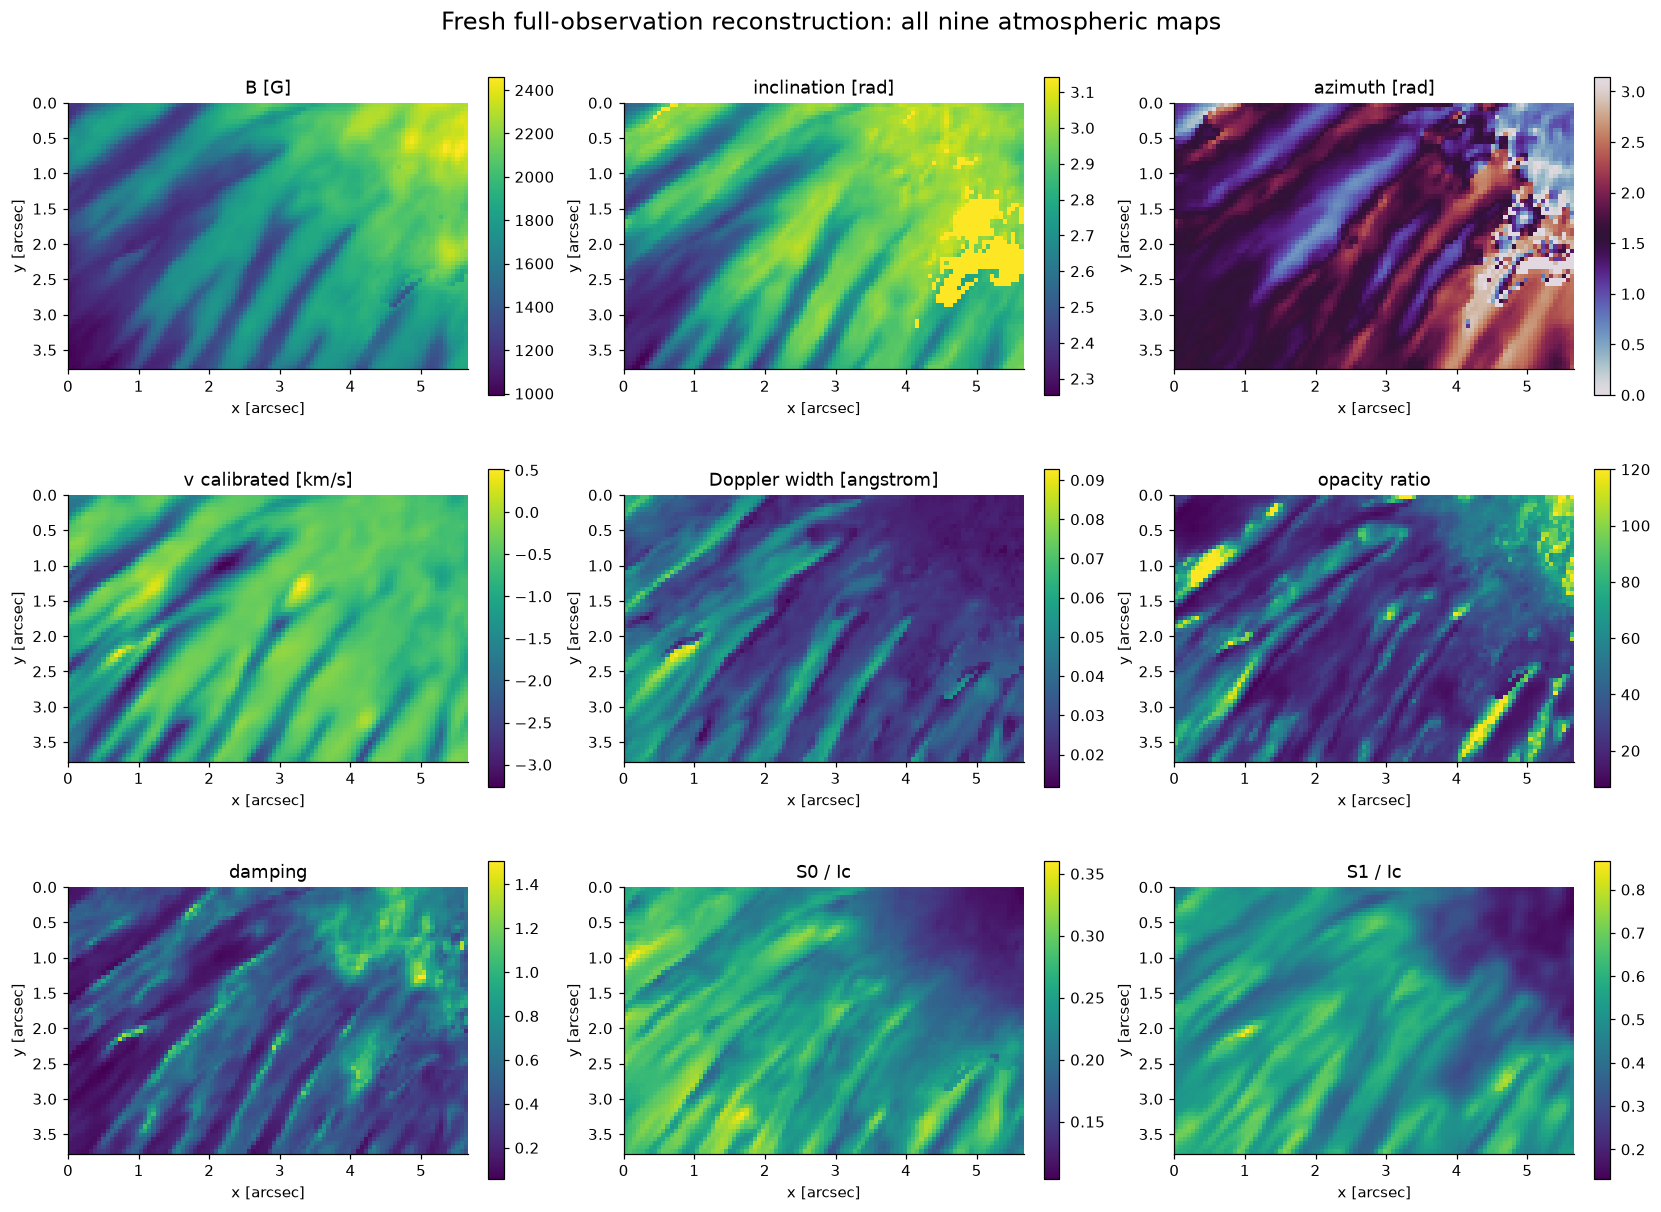

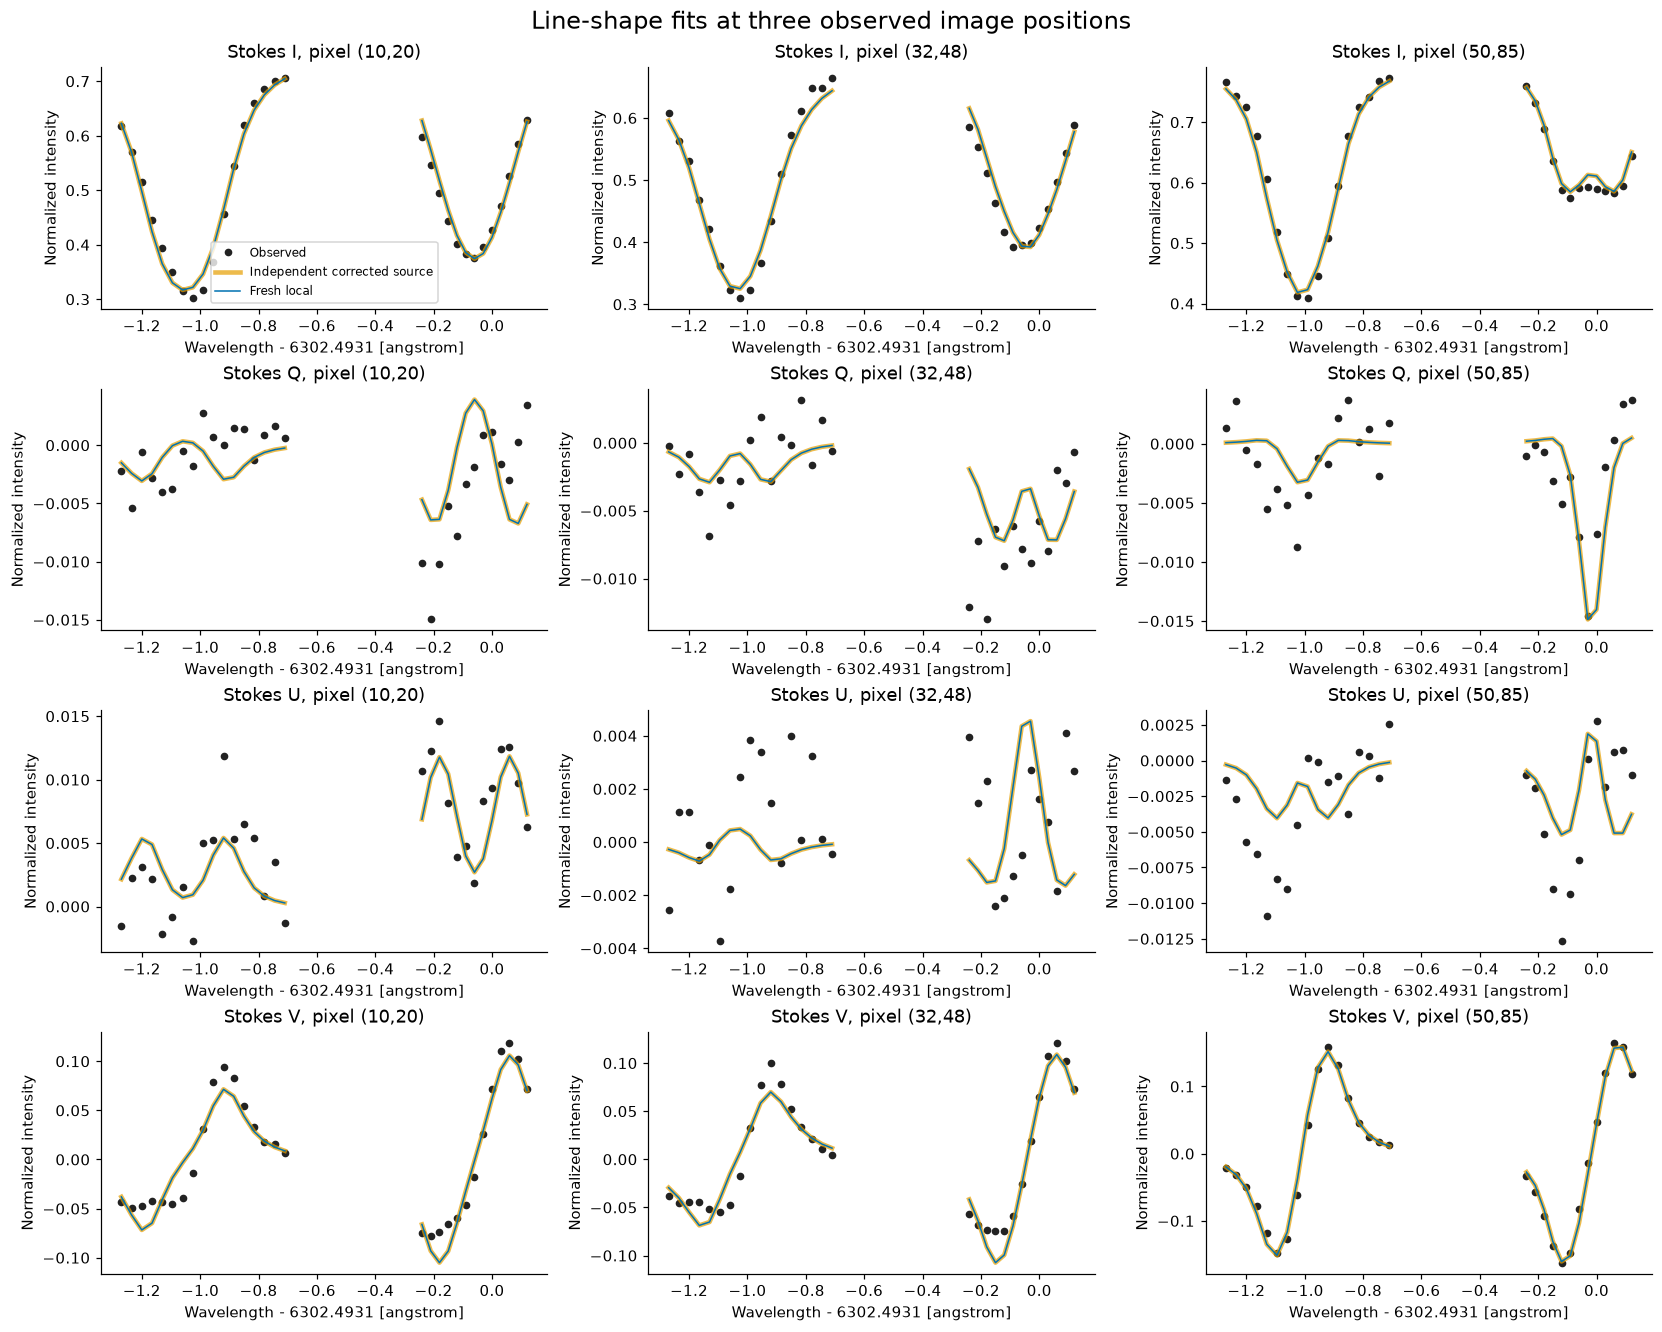

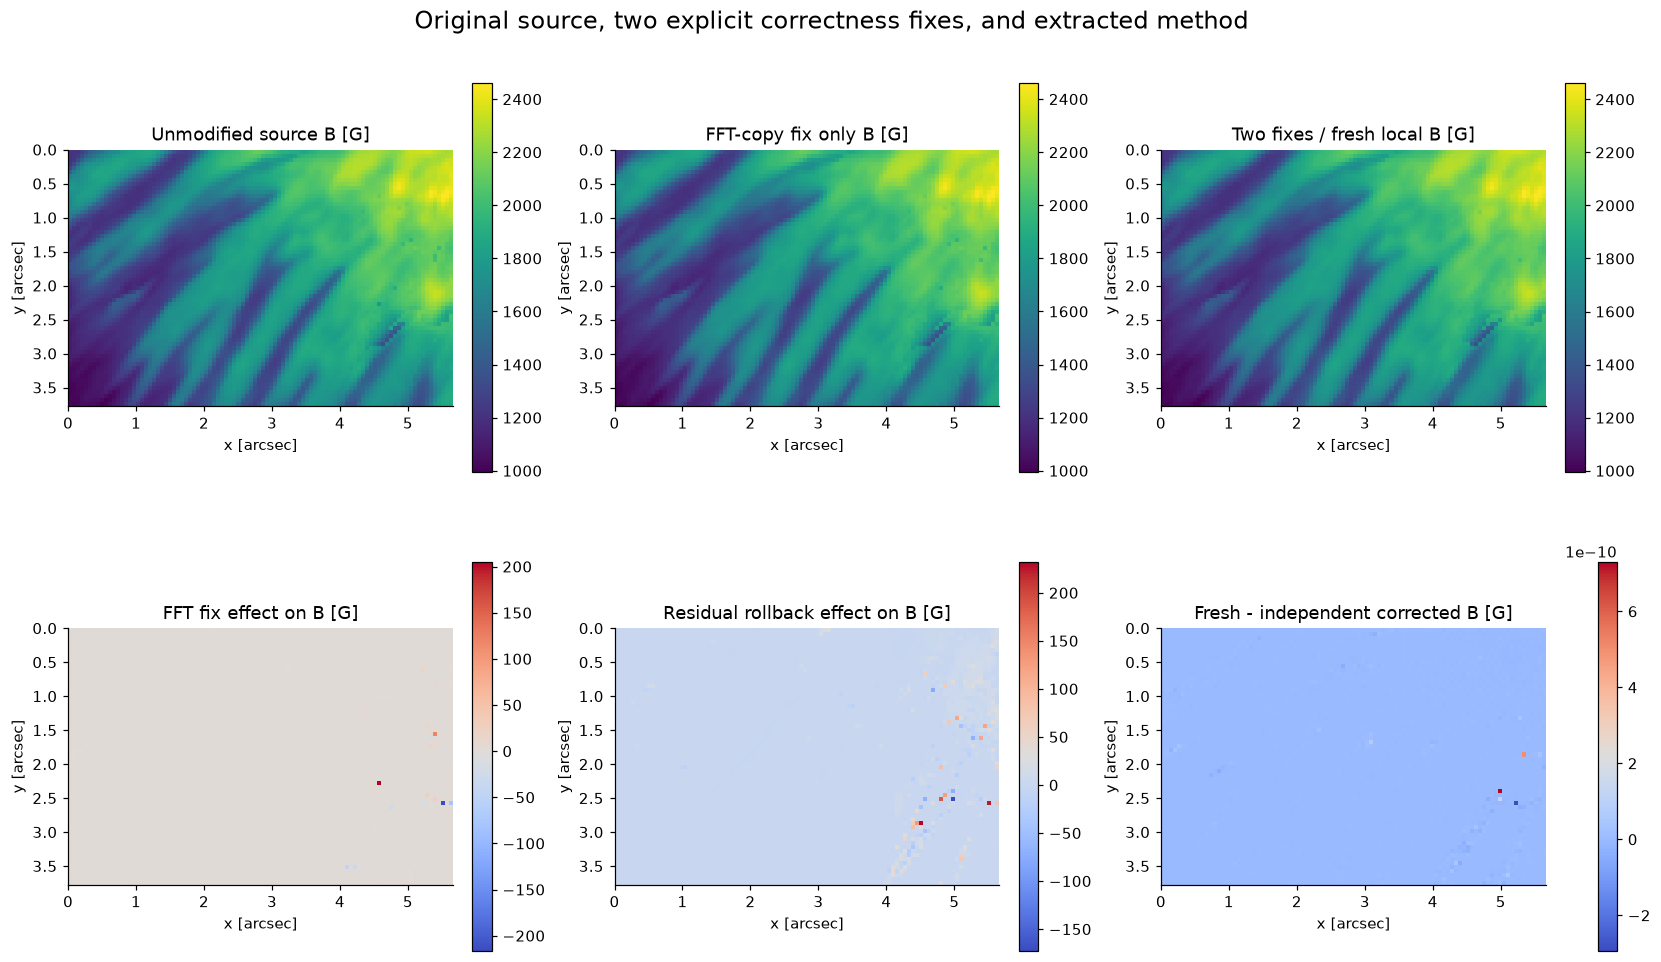

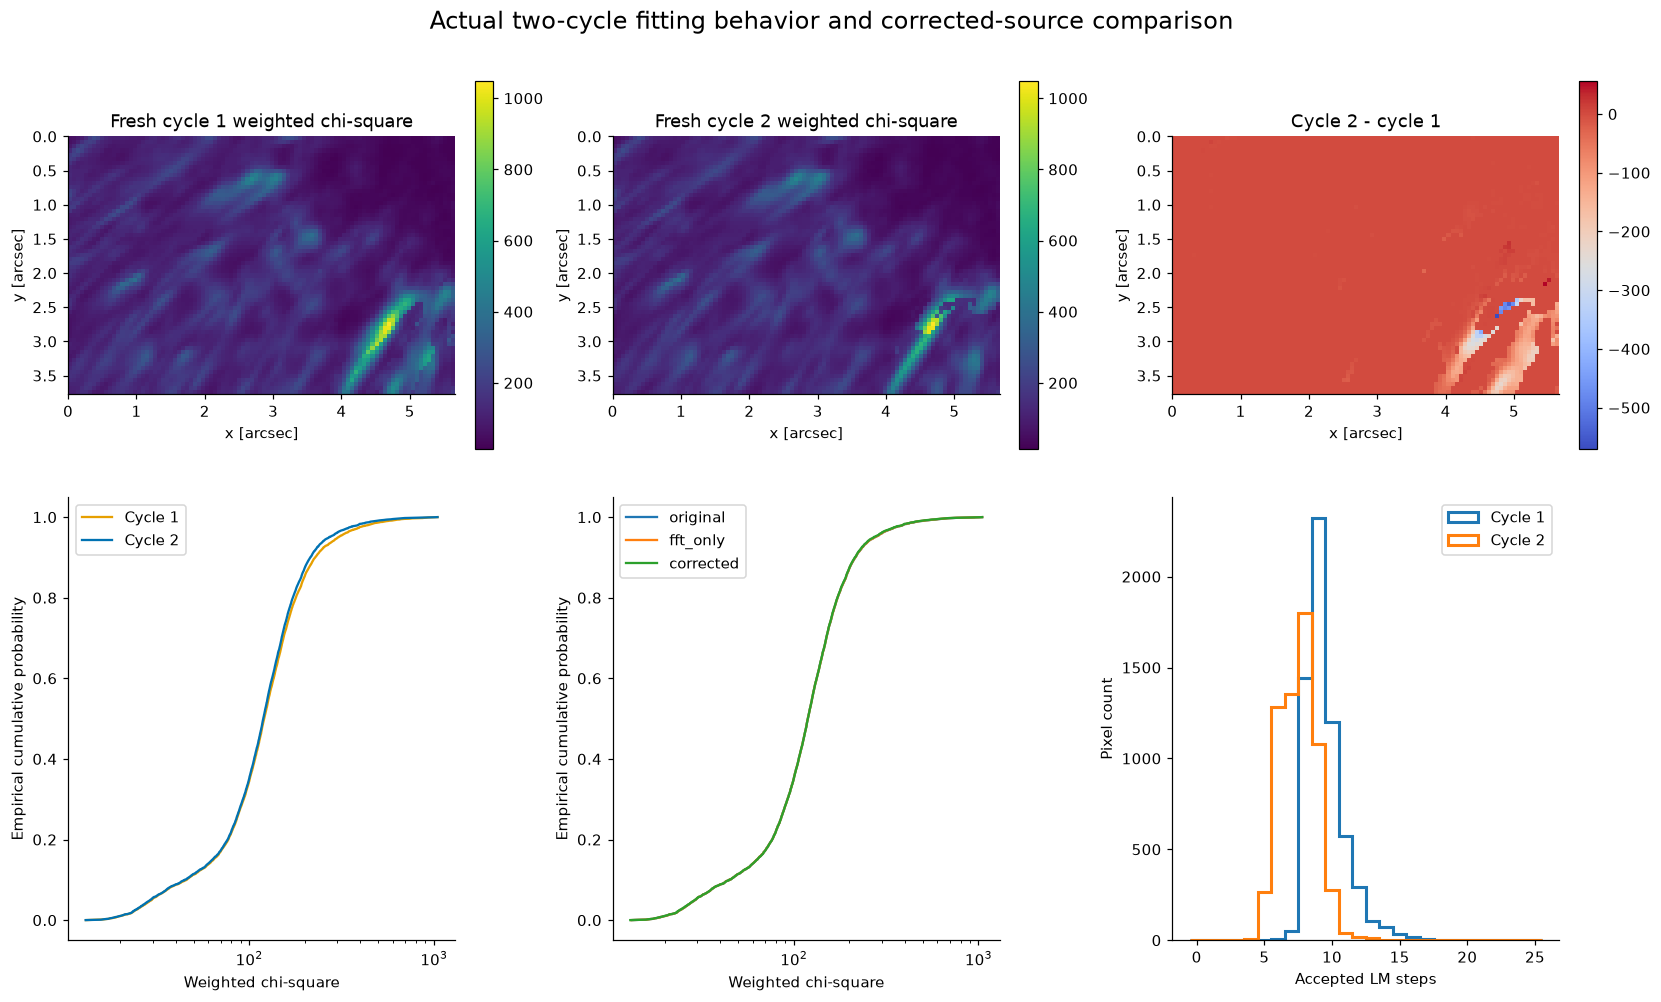

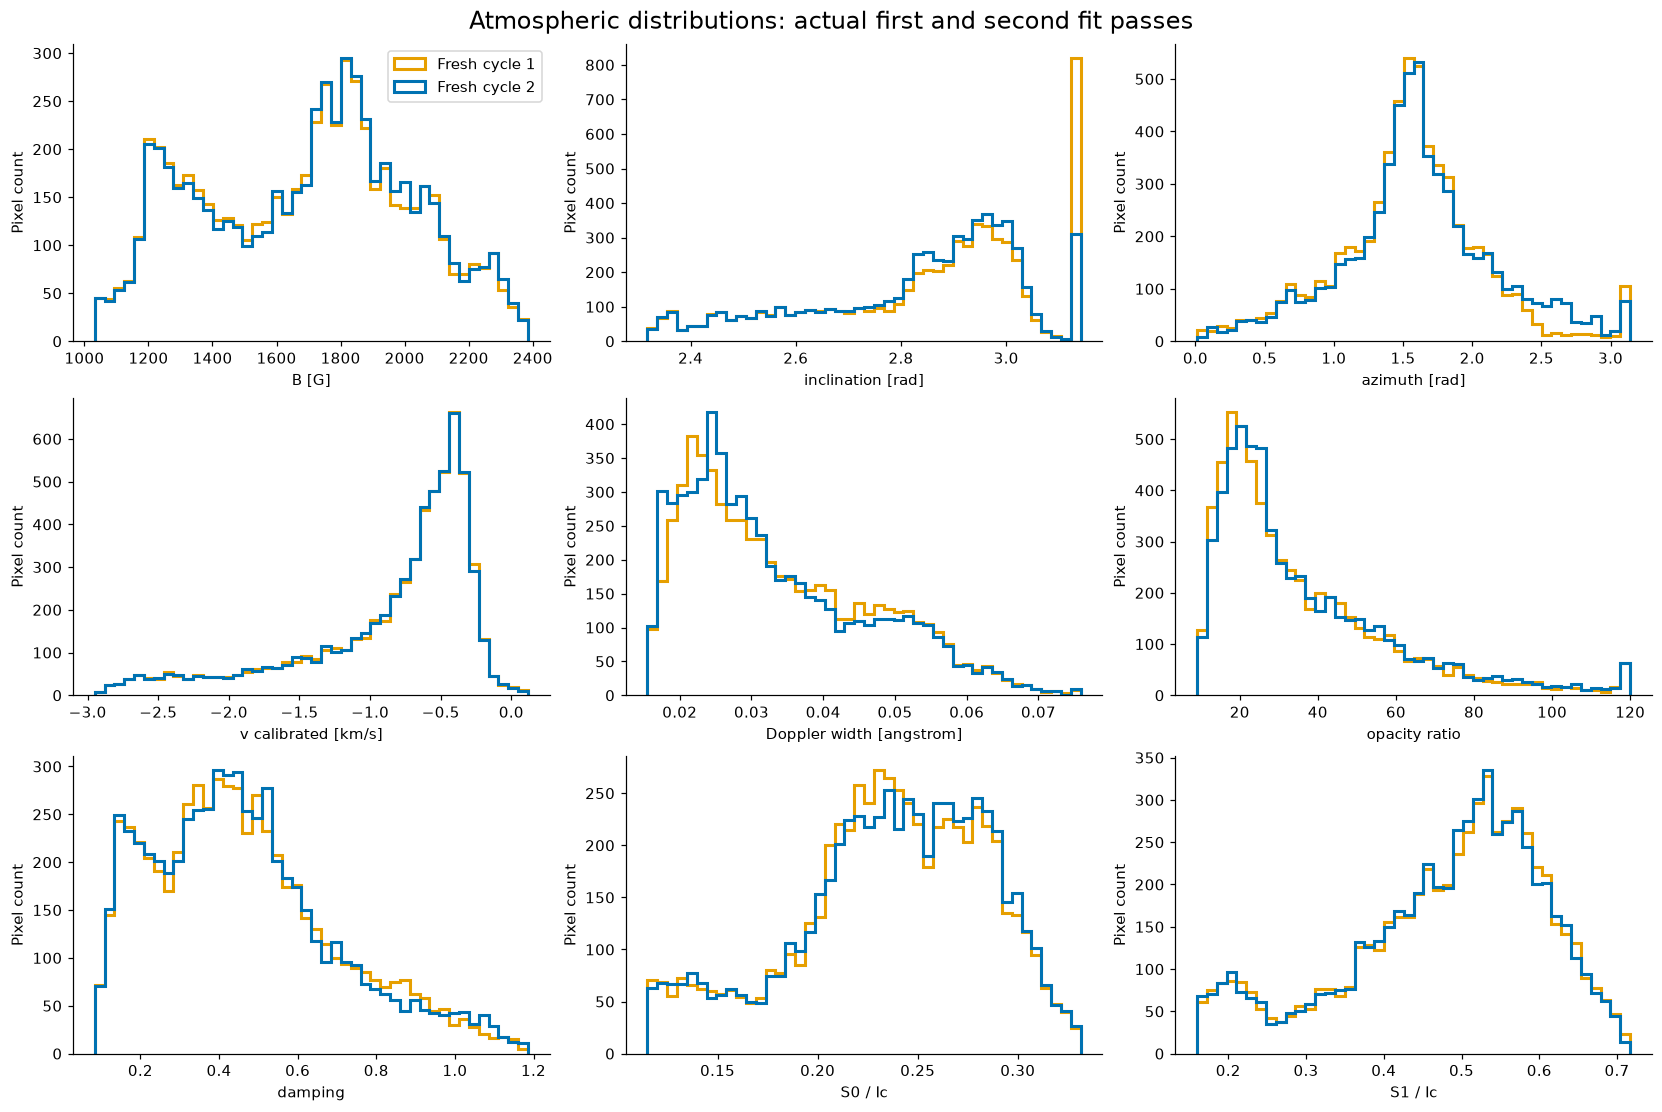

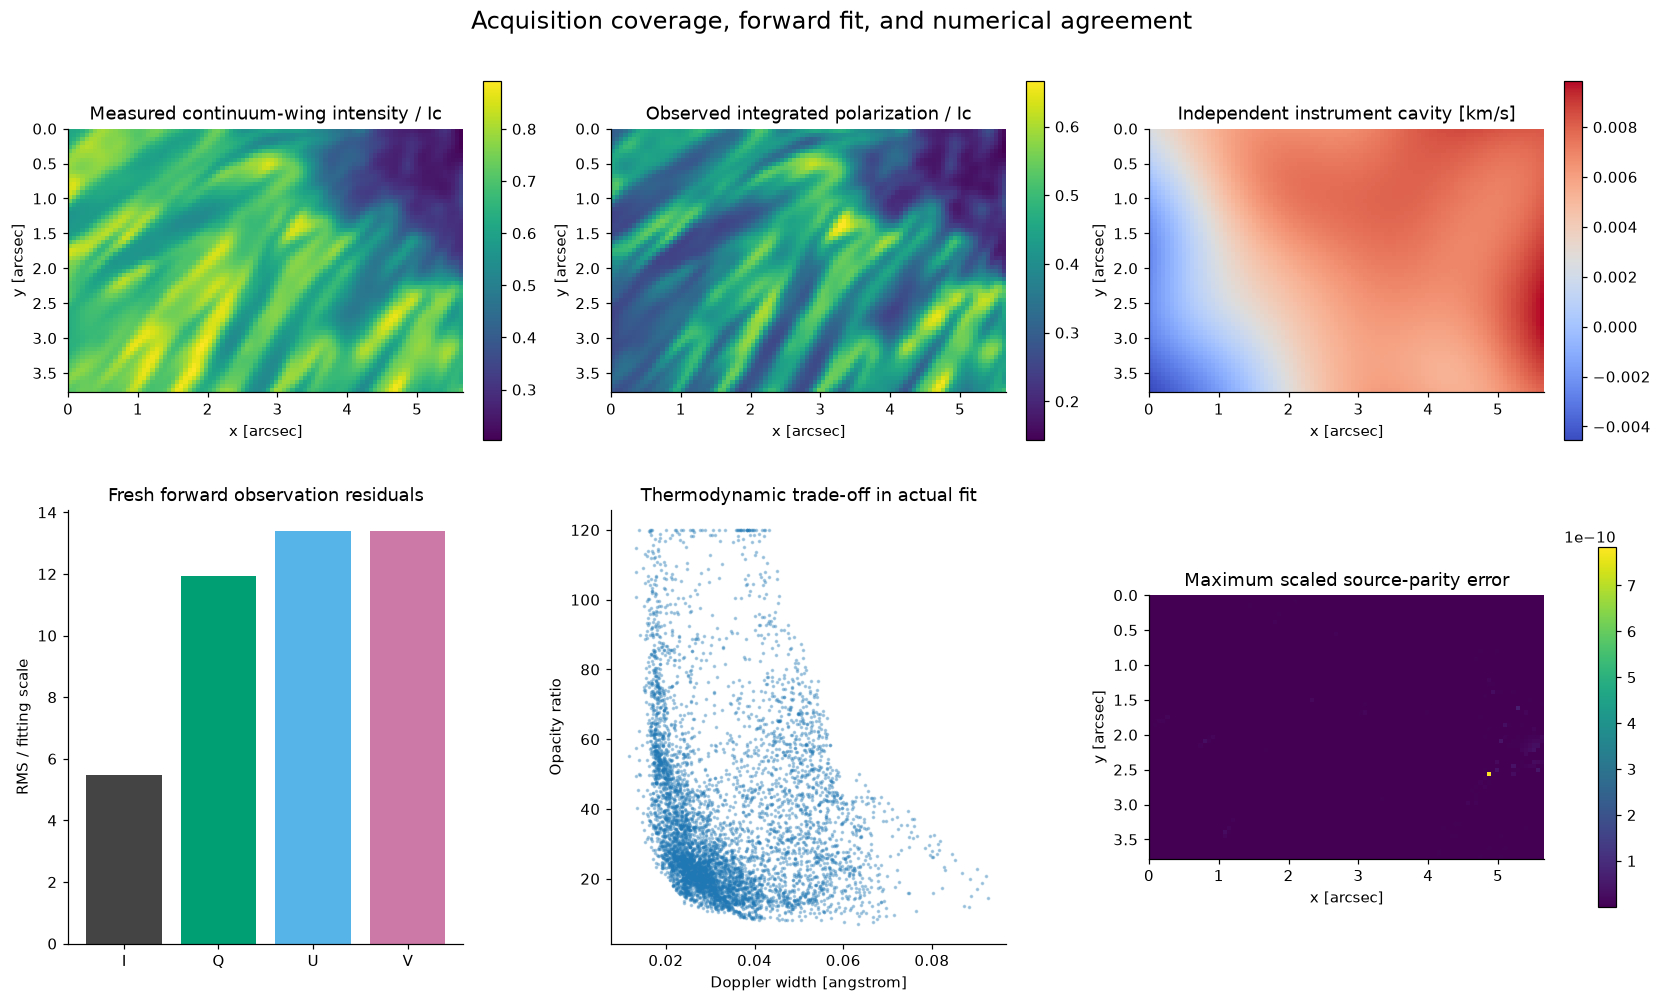

Scientific figure groups: 6 PNG/SVG/PDF and numerical source exports: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch5_20261021\astro_earth\figures\solar_crisp_stokes_vector_mapping
Maximum scaled independent-source discrepancy: 7.834657367311593e-10


In [3]:
refs={}
for name,filename in [('original','upstream_run.npz'),('fft_only','upstream_fft_only_run.npz'),('corrected','upstream_corrected_run.npz')]:
    with np.load(ROOT/'notebooks/reference_outputs'/filename,allow_pickle=False) as z: refs[name]={key:z[key].copy() for key in z.files}
figures,numeric_sources=make_figures(data,parameters,diagnostics,refs,export_dir=EXPORT)
for fig in figures:
    display(fig)
    plt.close(fig)
summary={'active_reconstruction_seconds':reconstruction_seconds,'judge':report,'source_scaled_max_error_by_parameter':np.max(np.abs(parameters-refs['corrected']['parameters'])/SCALE,axis=(0,1)).tolist(),'figure_count':len(figures)}
(EXPORT/'metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
print('Scientific figure groups:',len(figures),'PNG/SVG/PDF and numerical source exports:',EXPORT)
print('Maximum scaled independent-source discrepancy:',max(summary['source_scaled_max_error_by_parameter']))


## 6. Conclusion

### Interpretation and limitations

The actual multi-quantity maps and forward spectra agree with the independently corrected standard method. This establishes reproducible extraction of the selected transfer and inverse updates, not a unique physical atmosphere. The nonzero observation residuals reflect the depth-independent approximation and the deliberately enhanced polarization weighting. Width, opacity and damping trade off, and no height structure or azimuth disambiguation is claimed. The notebook retains original/corrected distinctions and all six executed scientific comparison groups; full commands, hashes, environments and gate evidence are indexed in `test/validation.md`.
